In [2]:

# MINI PROJECT: FASHION ITEM RECOGNITION

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# 1. LOAD AND VISUALIZE DATASET

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

In [3]:
names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
         "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

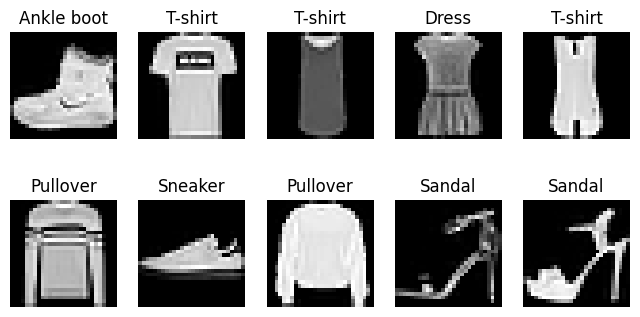

In [4]:
# Display 10 images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(names[y_train[i]])
    plt.axis("off")

plt.show()

In [5]:
# Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

In [6]:
# 2. FULLY CONNECTED NEURAL NETWORK

dense_model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training Fully Connected Model")

dense_history = dense_model.fit(
    x_train, y_train,
    epochs=3,
    validation_split=0.1
)

dense_loss, dense_acc = dense_model.evaluate(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Fully Connected Model
Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8203 - loss: 0.5111 - val_accuracy: 0.8523 - val_loss: 0.4058
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8631 - loss: 0.3792 - val_accuracy: 0.8667 - val_loss: 0.3560
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8769 - loss: 0.3360 - val_accuracy: 0.8715 - val_loss: 0.3527
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8678 - loss: 0.3704


In [7]:
# 3. BUILD CNN MODEL

x_train_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_cnn = x_test.reshape(-1, 28, 28, 1)

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training CNN Model")

cnn_history = cnn_model.fit(
    x_train_cnn, y_train,
    epochs=3,
    validation_split=0.1
)

cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test)

Training CNN Model
Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - accuracy: 0.8470 - loss: 0.4326 - val_accuracy: 0.8872 - val_loss: 0.3157
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.8942 - loss: 0.2958 - val_accuracy: 0.8945 - val_loss: 0.2911
Epoch 3/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.9085 - loss: 0.2537 - val_accuracy: 0.8955 - val_loss: 0.2831
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8923 - loss: 0.2905


In [8]:
# 4. COMPARE MODELS

print("\nMODEL COMPARISON")
print("Fully Connected Accuracy:", round(dense_acc * 100, 2), "%")
print("CNN Accuracy:", round(cnn_acc * 100, 2), "%")


MODEL COMPARISON
Fully Connected Accuracy: 86.78 %
CNN Accuracy: 89.23 %


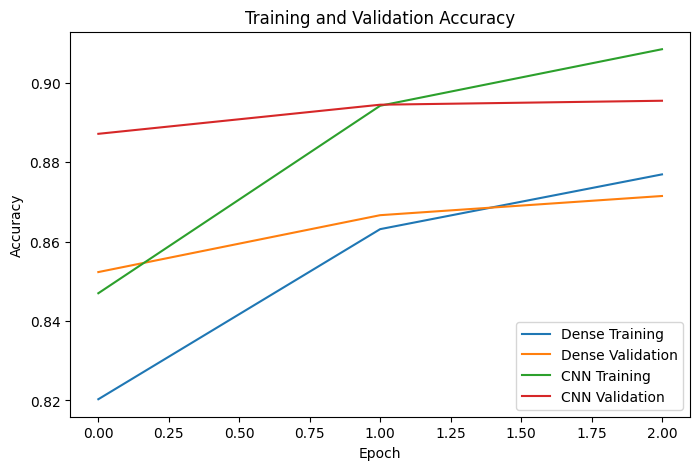

In [9]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(dense_history.history["accuracy"], label="Dense Training")
plt.plot(dense_history.history["val_accuracy"], label="Dense Validation")
plt.plot(cnn_history.history["accuracy"], label="CNN Training")
plt.plot(cnn_history.history["val_accuracy"], label="CNN Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

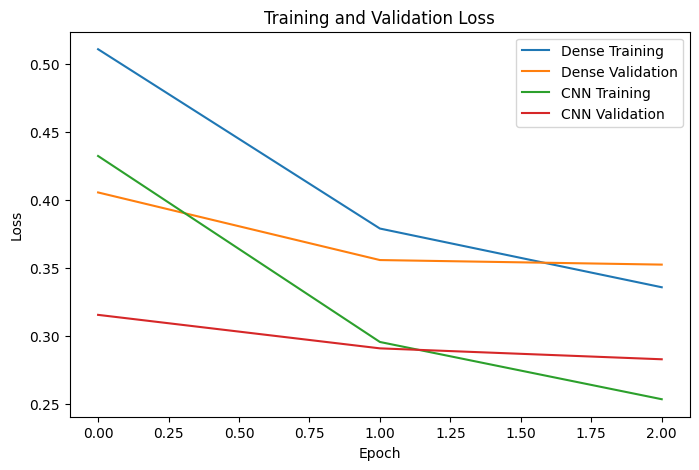

In [10]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(dense_history.history["loss"], label="Dense Training")
plt.plot(dense_history.history["val_loss"], label="Dense Validation")
plt.plot(cnn_history.history["loss"], label="CNN Training")
plt.plot(cnn_history.history["val_loss"], label="CNN Validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step

Example 1
Actual: Sneaker
Predicted: Bag
Reason: Similar clothing shapes or unclear image details.

Example 2
Actual: Ankle boot
Predicted: Sandal
Reason: Similar clothing shapes or unclear image details.

Example 3
Actual: T-shirt
Predicted: Shirt
Reason: Similar clothing shapes or unclear image details.

Example 4
Actual: Shirt
Predicted: T-shirt
Reason: Similar clothing shapes or unclear image details.

Example 5
Actual: Dress
Predicted: Shirt
Reason: Similar clothing shapes or unclear image details.


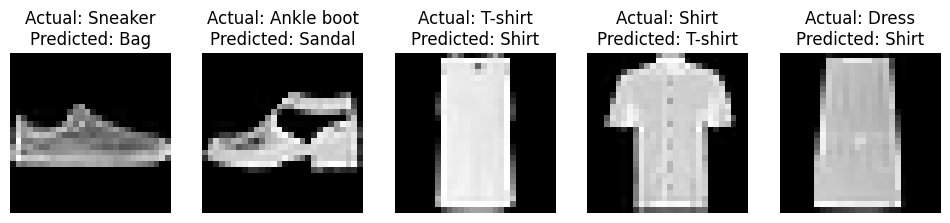

In [11]:
# 5. FIND FIVE MISCLASSIFIED IMAGES

predictions = cnn_model.predict(x_test_cnn)
predicted_labels = np.argmax(predictions, axis=1)

wrong = np.where(predicted_labels != y_test)[0]

plt.figure(figsize=(12, 5))

for i in range(5):
    index = wrong[i]

    actual = names[y_test[index]]
    predicted = names[predicted_labels[index]]

    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[index], cmap="gray")
    plt.title("Actual: " + actual + "\nPredicted: " + predicted)
    plt.axis("off")

    print("\nExample", i + 1)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Reason: Similar clothing shapes or unclear image details.")

plt.show()

In [12]:
# SAVE THE TRAINED CNN MODEL

cnn_model.save("fashion_mnist_cnn.keras")

print("\nCNN model saved successfully!")


CNN model saved successfully!
